# Spike detection

`detect_spikes` finds the spikes of one sweep, exactly like
`EphysSweepFeatureExtractor.process_spikes` of the AllenSDK, and `spike_features`
returns Allen's spike table. The examples use a cell from the [Allen Cell Types Database](https://celltypes.brain-map.org), loaded with a helper of this repository's tests. With your own recordings, all you need are NumPy arrays of time `t` (s), membrane potential `v` (mV) and, optionally, the injected current `i` (pA).

In [1]:
import sys
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

jax.config.update("jax_enable_x64", True)  # float64: results match Allen exactly

# Recordings from the Allen Cell Types Database, as downloaded for the tests
# (uv run python tests/load_testdata.py), read with a helper of the test suite.
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
sys.path.insert(0, str(REPO))

from jaxley_ephys import detect_spikes, spike_features  # noqa: E402

401000 samples at 50 kHz, step 1.02-2.02 s


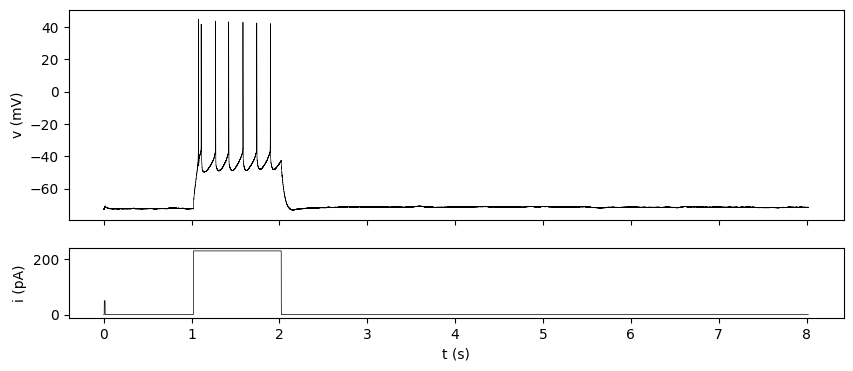

In [2]:
from tests.utils.allen_dataset import load_specimen_case  # noqa: E402 (uses AllenSDK)

case = load_specimen_case(519832676, data_root=str(REPO / "tests/testdata/allen_cache"))

# A long square: a 1 s current step that makes the cell fire
number = case.records(kind="long_square", has_spikes=True)[-1].sweep_number
t, v, i, start, end = case.trace_for(number)  # s, mV, pA; the step from start to end
print(
    f"{t.size} samples at {1e-3 / (t[1] - t[0]):.0f} kHz, step {start:.2f}-{end:.2f} s"
)

fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True, height_ratios=(3, 1))
axes[0].plot(t, v, "k", lw=0.5)
axes[1].plot(t, i, "k", lw=0.5)
axes[0].set(ylabel="v (mV)")
axes[1].set(xlabel="t (s)", ylabel="i (pA)")
plt.show()

## Detecting spikes

Pass the trace and the analysis window (`start`, `end`). All other parameters
(`dv_cutoff`, `thresh_frac`, `min_peak`, ...) and their defaults are Allen's.

In [3]:
sp = detect_spikes(t, v, i, start, end)
n = int(sp.n_spikes)
print(f"{n} spikes, thresholds at samples {sp.threshold[:n]}")

7 spikes, thresholds at samples [53825 55421 63579 71057 79191 87036 94786]


`detect_spikes` returns a `Spikes` object. It holds the traces (`sp.t`, `sp.v`,
`sp.i` and the low-pass filtered `sp.dvdt` in V/s) and, for every spike, the sample
indices of its threshold, peak, trough, upstroke, downstroke, fast trough and more.
These buffers have a fixed length (`max_spikes`, by default 256) so that everything
can be compiled: the spikes come first, missing entries are -1.

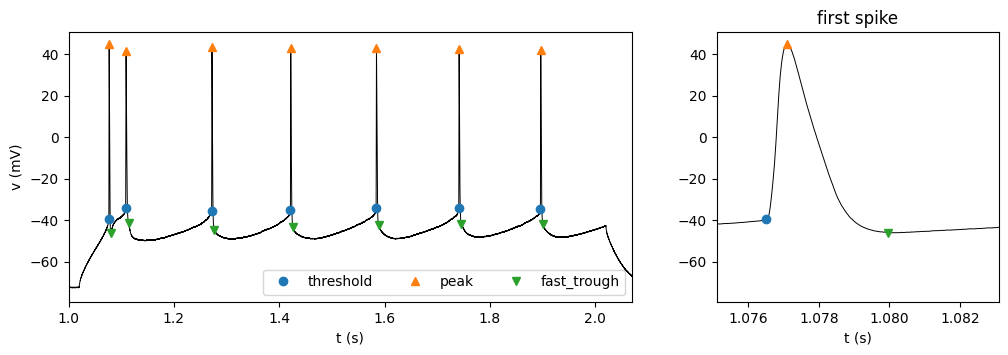

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), width_ratios=(2, 1))
for ax in axes:
    ax.plot(t, v, "k", lw=0.7)
    for name, marker in [("threshold", "o"), ("peak", "^"), ("fast_trough", "v")]:
        idx = np.asarray(getattr(sp, name))[:n]
        ax.plot(t[idx[idx >= 0]], v[idx[idx >= 0]], marker, label=name)
first = int(sp.peak[0])
axes[0].set(xlim=(start - 0.02, end + 0.05), xlabel="t (s)", ylabel="v (mV)")
axes[1].set(
    xlim=(t[first] - 0.002, t[first] + 0.006), xlabel="t (s)", title="first spike"
)
axes[0].legend(ncol=3, loc="lower right")
plt.show()

## Spike features

`spike_features` returns the columns of Allen's spike table as arrays of length
`max_spikes`: times in s, voltages in mV, currents in pA and dV/dt in V/s
(`upstroke`, `downstroke`), NaN where undefined.

In [5]:
features = spike_features(sp)
table = pd.DataFrame({name: np.asarray(x)[:n] for name, x in features.items()})
table[["threshold_t", "threshold_v", "peak_v", "fast_trough_v", "width", "upstroke"]]

,threshold_t,threshold_v,peak_v,fast_trough_v,width,upstroke
0,1.07650,-39.593752,44.718754,-45.937501,0.00118,283.103343
1,1.10842,-34.156252,41.656252,-41.468751,0.00164,200.041537
2,1.27158,-35.500001,43.562502,-44.562504,0.00136,227.378005
3,1.42114,-35.062503,43.125004,-43.437503,0.00134,223.305434
4,1.58382,-34.281250,42.843752,-42.500000,0.00132,212.314139
5,1.74072,-34.156252,42.437501,-41.875001,0.00134,210.401313
6,1.89572,-34.750003,42.031251,-42.031251,0.00138,203.897371


## What is analysed

Only spikes that start in `[start, end]` are detected. Samples more than about
20 ms after `end` cannot affect any result, so they are not analysed: they are NaN
in the returned traces. `t_cutoff` moves this point (`t_cutoff=float("inf")`
analyses the whole sweep).

In [6]:
analysed = ~np.isnan(np.asarray(sp.t))
print(
    f"analysed {analysed.sum()} of {t.size} samples, up to t = {t[analysed][-1]:.3f} s"
)

analysed 102075 of 401000 samples, up to t = 2.041 s
